# 70_hybrid: hierarchical Bayesian degradation curve anchored to the latest observation

**Owner:** Khải Hưng · **Design:** `docs/Rec.md` section 8 (committed **before** the test cells were scored) · **Code:** `src/hybrid_model.py`

**Why a fifth model.** In E2 (multi-step from the 60% origin) the four original models all lose to naive, and almost all of them forecast faster ageing than observed
(`60_compare`). Naive, in turn, never warns that a cell will reach end of life. The business question is *when to replace a cell*, so the fifth model targets the
multi-step trajectory, the RUL and the EOL alarm.

**What it combines (the "hybrid").**
1. **Population curve** learned from the 8 training cells: `SOH(t) = c − a·t^b`, with `b < 1` meaning ageing that slows down.
2. **The cell's own history** before the origin, which updates that curve by Bayes' rule (MAP with a Gaussian prior). Because consecutive cycles are strongly
   autocorrelated, the cell's own data get weight `w = 0.03`.
3. **Persistence**: the curve is anchored to the mean of the last 5 observed SOH values, so the forecast starts from where the cell is now.

**Honesty note.** The model was designed after the first four models had been scored on the test cells. Every design choice (curve form, `w`, anchor, E1 rule) was
made by leave-one-cell-out cross-validation on the 8 training cells with a pseudo 60% origin, and the test cells were scored once.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import protocol as P
import hybrid_model as Hm

out = Hm.run()          # training-cell CV, the single test run, all output files
pd.set_option("display.precision", 4)
print("E1 interval half-width (95th percentile of |error| in training-cell CV):", round(out["q_e1"], 4))

E1 interval half-width (95th percentile of |error| in training-cell CV): 0.0324


## Step 1. Design evidence: cross-validation on the training cells only

Each training cell in turn plays the test cell: the prior comes from the other 7 cells, the history is its first 60%, and the forecast is scored on the rest
(383 E2 rows, 91 alarm rows). No test cell is used.

In [2]:
out['cv_metrics']

,model,scenario,n,MAE,RMSE,MAPE_pct,R2
0,hybrid,E1,383,0.0081,0.0157,0.9964,0.9543
1,hybrid,E2,383,0.0237,0.0314,3.0810,0.8177
2,naive,E1,383,0.0087,0.0156,1.0806,0.9550
3,naive,E2,383,0.0365,0.0472,5.0702,0.5872


In [3]:
out['cv_alarm']

,model,TP,FN,FP,TN,sensitivity,specificity,precision,accuracy
0,naive,0,29,0,62,0.0,1.0000,NaN,0.6813
1,hybrid,29,0,18,44,1.0,0.7097,0.617,0.8022


**Reading.** On the training cells the hybrid cuts the E2 MAE from 0.0365 (naive) to 0.0237 and raises an alarm before every EOL (sensitivity 1.00, specificity 0.71),
while naive never alarms. In E1 the gain is small (0.0081 vs 0.0087). Adding the rest-time effect `log1p(rest_before_h)` to E1 did not help in this CV (0.0084), so it is not used
(Rec.md 8 #5). These numbers are optimistic, because `w` was chosen on the same 8 cells.

## Step 2. Test cells (single run)

In [4]:
metrics, rul = P.evaluate(out["pred"])
metrics

,model,scenario,battery_id,n,MAE,RMSE,MAPE_pct,R2
0,hybrid,E1,B0007,67,0.0025,0.0036,0.3109,0.9793
1,hybrid,E1,B0034,78,0.0085,0.0135,1.0142,0.4246
2,hybrid,E1,B0047,28,0.0086,0.0176,1.0821,0.0371
3,hybrid,E1,B0055,40,0.0348,0.0461,4.1055,-1.2913
4,hybrid,E2,B0007,67,0.0115,0.0149,1.4957,0.6451
5,hybrid,E2,B0034,78,0.0215,0.0283,2.5705,-1.5257
6,hybrid,E2,B0047,28,0.0464,0.0567,5.8759,-9.0512
7,hybrid,E2,B0055,40,0.0265,0.0380,3.0926,-0.5534
8,hybrid,E1,all,213,0.0115,0.0226,1.3824,0.5001
9,hybrid,E2,all,213,0.0226,0.0325,2.7650,-0.0343


In [5]:
rul

,model,battery_id,eol_true,eol_pred,rul_error
0,hybrid,B0007,126,122,-4
1,hybrid,B0034,186,167,-19
2,hybrid,B0055,65,97,32


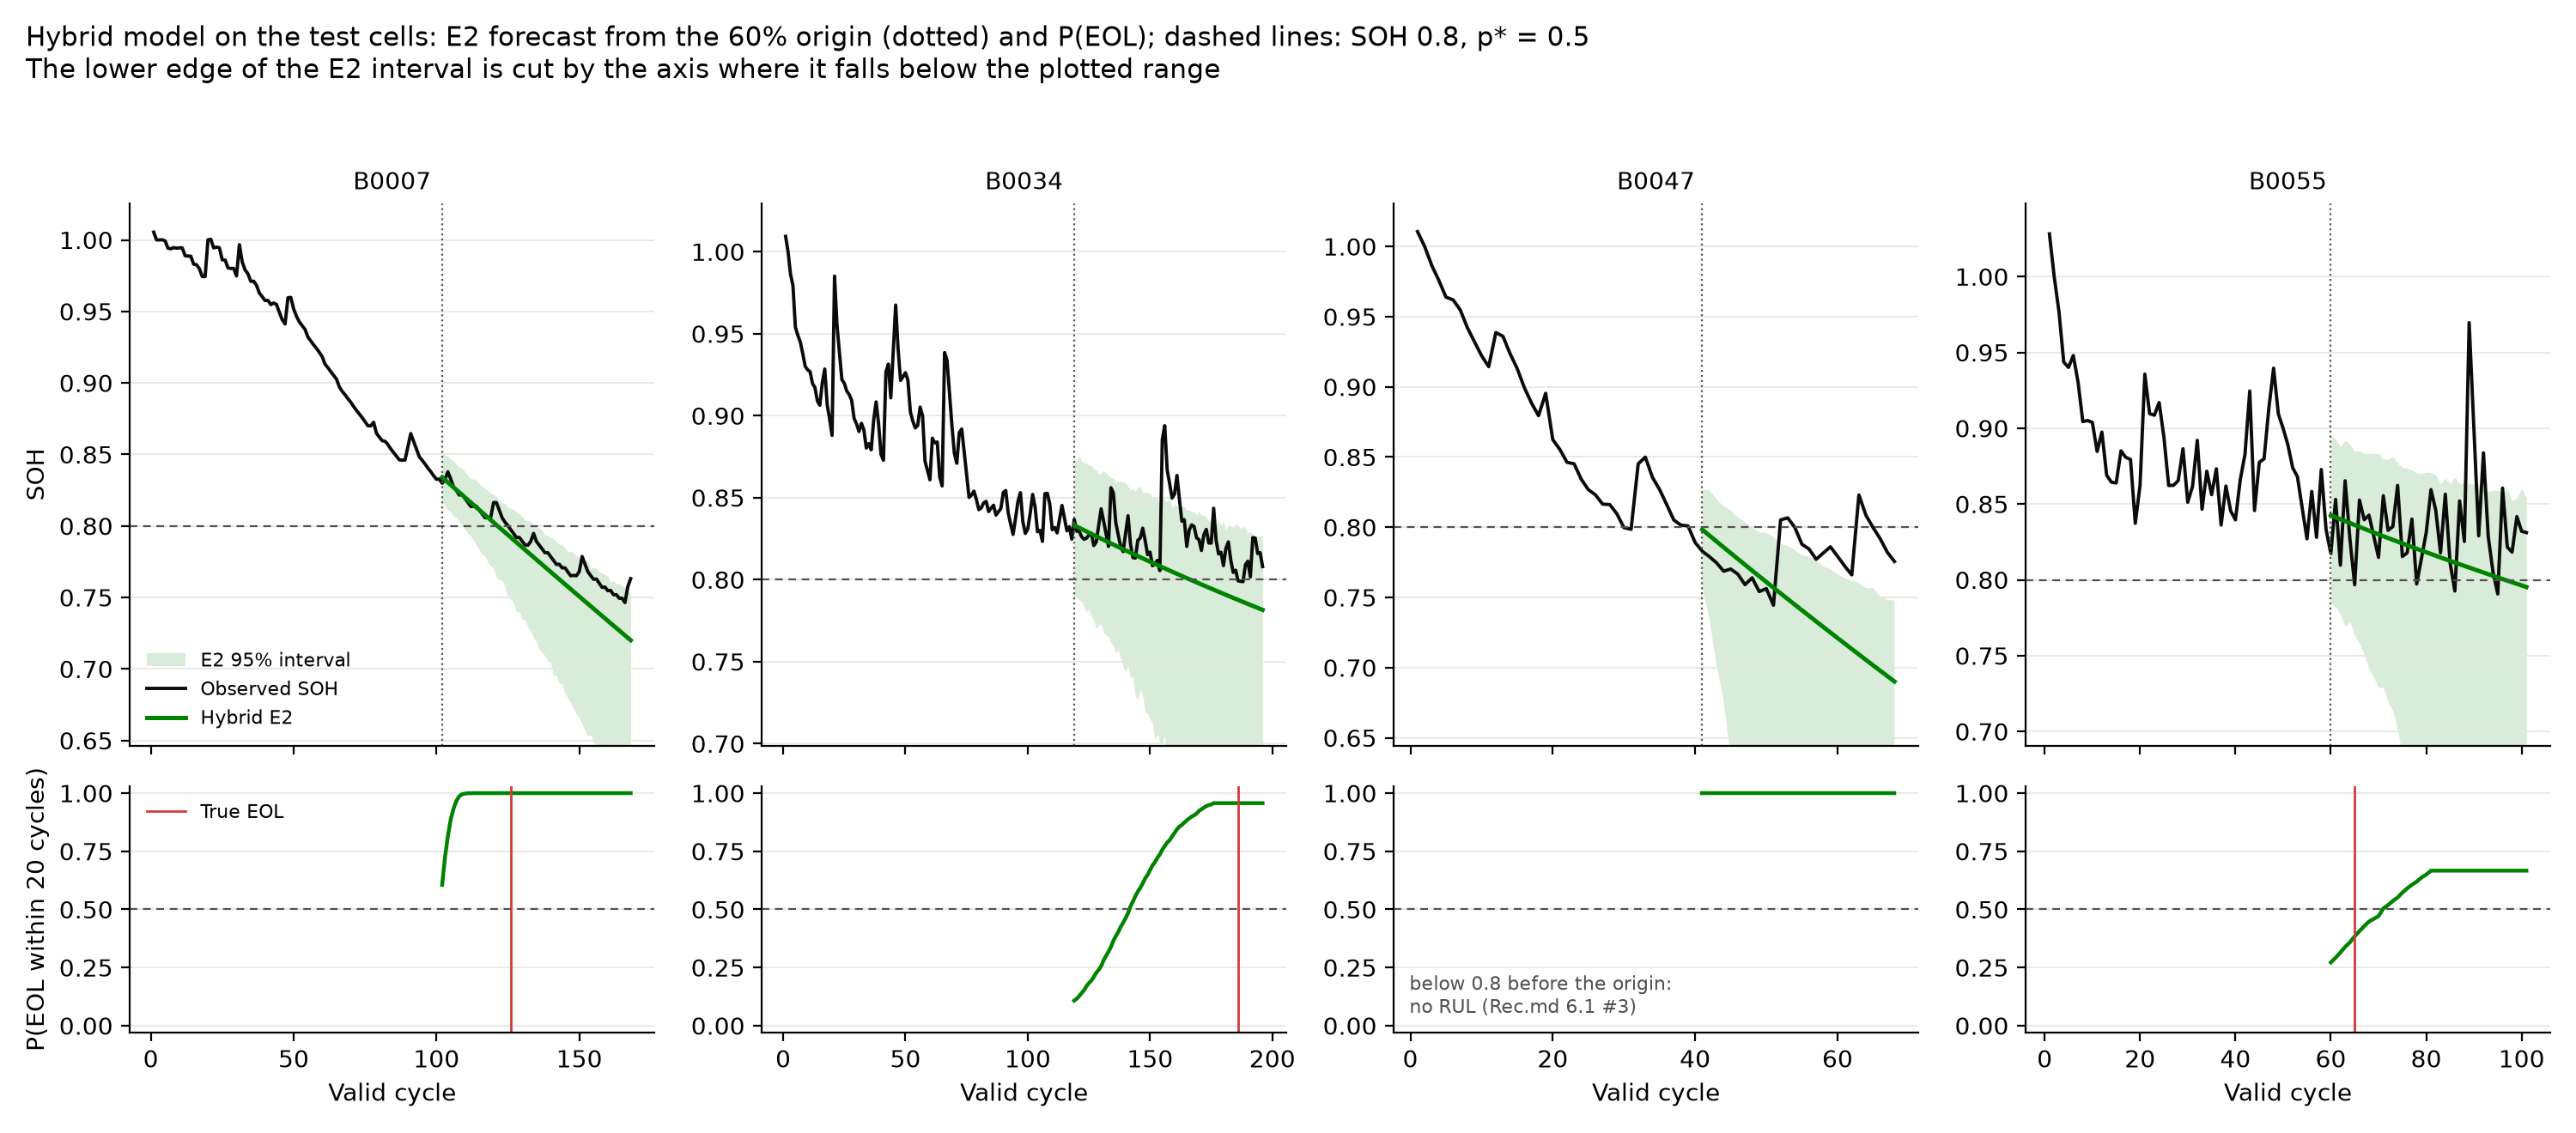

In [6]:
display(Image(str(ROOT / 'reports/figures/hybrid_test.png')))

In [7]:
pd.read_csv(ROOT / 'reports/tables/hybrid_parameters.csv')

,battery_id,c,a,b,noise_sd,anchor_level
0,B0007,1.0321,0.0029,0.9131,0.0092,0.8358
1,B0034,0.9977,0.0135,0.5300,0.0216,0.8339
2,B0047,0.9992,0.0111,0.8000,0.0160,0.8026
3,B0055,0.9757,0.0131,0.5719,0.0274,0.8439


**Reading.**
- **E2:** pooled MAE 0.0226, the only model below naive (0.0249), but the gain comes from B0007 (0.0115 vs 0.0452 for naive). On the three almost-flat cells naive is better
  (B0034 0.0215 vs 0.0124, B0047 0.0464 vs 0.0167, B0055 0.0265 vs 0.0209).
- **Shape:** the fitted exponent `b` is 0.53 for B0034 and 0.57 for B0055 (ageing that slows down) and 0.91 for B0007 (almost linear), learned from each cell's own history
  through the prior. This is why the hybrid falls more slowly than ARIMA, SVR and LSTM on B0034.
- **RUL:** −4 cycles on B0007 and −19 on B0034 (the smallest errors of all models on these two cells), but +32 on B0055, which only just dips below 0.8.
- **P(EOL):** on B0007 and B0034 the probability rises above 0.5 before the true EOL (cycles 102 and 142 vs 126 and 186); on B0055 it only reaches 0.5 at cycle 71, after the true EOL (65).
- **Intervals:** the E1 interval covers 90.1% and the E2 interval 85.0% of the true values (nominal 95%). The lower edge of the E2 interval is very wide and falls to
  physically impossible values at long horizons (for B0047 below 0), because the posterior allows curves that fall fast. It should be read as a sign of how uncertain the long-run shape is, not as a usable bound.

## Step 3. Is the difference significant? Diebold–Mariano test

`mean_diff` = mean of (|error of the other model| − |error of the hybrid|), > 0 when the hybrid is better. Newey–West variance, autocovariances only within a cell.

In [8]:
out['dm']

,scenario,hybrid_vs,mean_diff,DM,p,n,lag
0,E1,naive,0.0004,2.9738,2.9415e-03,213,4
1,E1,lstm,-0.0017,-3.3920,6.9381e-04,213,4
2,E2,naive,0.0023,0.5366,5.9156e-01,213,4
3,E2,lstm,0.0077,4.1978,2.6946e-05,213,4


**Reading.** In E2 the hybrid is significantly better than LSTM (p < 0.001), but **not** significantly better than naive (p = 0.59). In E1 it is significantly better than naive
(p = 0.003) but significantly worse than LSTM (p < 0.001). The report must say that the E2 advantage over naive is not statistically established on four test cells.

## Step 3b. Robustness: the same frozen model on all 12 tier-A cells

Four test cells give little statistical power. As a **supporting** check (added after the test run, Rec.md section 8 update), the frozen design is applied without any
change in leave-one-cell-out over all 12 tier-A cells: each cell in turn is forecast from its own 60% origin with the prior learned from the other 11 cells.
Caveat: `w` was chosen on 8 of these 12 cells, so this check is not independent of the design; the confirmatory result remains the single test run above.

In [9]:
out['loco_metrics']

,model,scenario,n,MAE,RMSE,MAPE_pct,R2
0,hybrid,E1,596,0.0094,0.0184,1.1498,0.9195
1,hybrid,E2,596,0.0184,0.0249,2.3793,0.8535
2,naive,E1,596,0.0098,0.0184,1.2050,0.9197
3,naive,E2,596,0.0323,0.0431,4.3757,0.5605


In [10]:
out['loco_dm']

,scenario,hybrid_vs,mean_diff,DM,p,n,lag
0,E1,naive,0.0004,5.8019,6.5572e-09,596,5
1,E2,naive,0.0139,5.4676,4.5625e-08,596,5


In [11]:
out['loco_alarm']

,model,TP,FN,FP,TN,sensitivity,specificity,precision,accuracy
0,naive,0,74,0,113,0.0000,1.0000,NaN,0.6043
1,hybrid,61,13,21,92,0.8243,0.8142,0.7439,0.8182


In [12]:
out['loco_cells'][out['loco_cells'].scenario == 'E2']

model,scenario,battery_id,hybrid,naive,hybrid_better
12,E2,B0005,0.0087,0.0585,True
13,E2,B0006,0.0268,0.0612,True
14,E2,B0007,0.0108,0.0452,True
15,E2,B0018,0.0175,0.0317,True
16,E2,B0033,0.0222,0.0251,True
17,E2,B0034,0.0157,0.0124,False
18,E2,B0045,0.0132,0.0166,True
19,E2,B0046,0.0220,0.0239,True
20,E2,B0047,0.0221,0.0167,False
21,E2,B0048,0.0254,0.0170,False


**Reading.** Over 12 cells (596 E2 rows) the hybrid's E2 MAE is 0.0184 against 0.0323 for naive (43% lower), and the Diebold–Mariano test is significant (p < 0.001).
It is better than naive on 8 of the 12 cells; the four cells where naive wins (B0034, B0047, B0048, B0055) are the ones that stay almost flat after the origin.
As an alarm it reaches sensitivity 0.82 with specificity 0.81, while naive never alarms. In E1 the gain is small (0.0094 vs 0.0098) but consistent (10 of 12 cells, p < 0.001).
So the advantage seen on the four test cells is not an accident of B0007, but its size depends on whether a cell keeps ageing or levels off.

## Step 4. Business use: cost of a replacement policy (Rec.md 8 #9)

Each test cell that is still above SOH 0.8 at the origin (B0007, B0034, B0055) is followed from the origin. The operator **replaces the cell at the first alarm**.
- Replacing at cycle *t* before the true EOL wastes the remaining life: cost = EOL − *t* (in cycles of battery life).
- No alarm before the true EOL means an unplanned failure: cost = R, the failure cost expressed in cycles of battery life. R = 10, 20, 50, 100 covers cheap to very expensive failures.

Every model uses its point-forecast alarm (as in `60_compare`); `hybrid_p*` uses the hybrid's probability with threshold p* = 0.5.

In [13]:
cost = out["cost"]
cost.pivot_table(index="model", columns="ratio", values="cost", aggfunc="sum")

ratio,10,20,50,100
model,,,,
arima,101,111,141,191
arimax,39,49,79,129
hybrid,73,83,113,163
hybrid_p*,78,88,118,168
lstm,90,100,130,180
naive,30,60,150,300
regression,44,64,124,224
svr,101,111,141,191


In [14]:
cost[cost.ratio == 50].pivot_table(index="model", columns="battery_id", values=["replace_at", "wasted_cycles", "failure"], aggfunc="first")

failure               replace_at              wasted_cycles        \
battery_id   B0007  B0034  B0055      B0007  B0034 B0055         B0007 B0034   
model                                                                          
arima        False  False   True      102.0  119.0   NaN            24    67   
arimax       False   True  False      102.0    NaN  60.0            24     0   
hybrid       False  False   True      102.0  147.0   NaN            24    39   
hybrid_p*    False  False   True      102.0  142.0   NaN            24    44   
lstm         False  False   True      102.0  130.0   NaN            24    56   
naive         True   True   True        NaN    NaN   NaN             0     0   
regression   False   True   True      102.0    NaN   NaN            24     0   
svr          False  False   True      102.0  119.0   NaN            24    67   

                  
battery_id B0055  
model             
arima          0  
arimax         5  
hybrid         0  
hybrid_p*      0  
lstm           0  
naive          0  
regression     0  
svr            0

**Reading.**
- **Naive is cheapest only when failures are cheap.** It never replaces early, so it pays R on all three cells (3R). For R ≥ 50 it is the most expensive of all policies.
- **The hybrid** costs 63 cycles of wasted life plus one failure (B0055), i.e. 63 + R: cheaper than naive as soon as R > 31.5 cycles, and cheaper than ARIMA, SVR, LSTM and
  regression for R ≥ 50.
- **On these three cells ARIMAX has the lowest cost at every R** (29 wasted cycles + one failure on B0034). Its advantage comes from a single cell (B0055, where it alarms 5 cycles before EOL),
  so this ranking is fragile.
- **B0007:** every model alarms at the origin and replaces 24 cycles before EOL. With "replace at the first alarm" the policy always gives up close to H = 20 cycles; a policy that
  schedules the replacement at the predicted EOL would waste less. This is a limitation of the simple policy, not of a single model.

**Practical meaning.** For an operator whose unplanned failures cost more than about 30 cycles of battery life (stranded vehicle or drone, downtime, safety), a model that warns is clearly
better than waiting for the measured SOH to cross 0.8. Among the models, the hybrid gives the most balanced alarm (few misses, fewer false alarms than ARIMA/SVR/LSTM) and a
probability that the operator can tune to its own cost ratio. With three test cells these costs illustrate the decision, they do not estimate it.

## Step 5. Conclusions and limitations (for Report §5 and the paper)

1. On the four test cells the hybrid is the only model whose E2 MAE is below naive (0.0226 vs 0.0249), but the difference is not significant (DM p = 0.59) and comes from one steadily ageing cell (B0007).
   With the same frozen model over all 12 tier-A cells (supporting check, Step 3b) the gain is 43% (0.0184 vs 0.0323), significant (p < 0.001), and holds on 8 of 12 cells.
2. It is significantly better than the best original model in E2 (LSTM, p < 0.001), reaches EOL on all three cells, and has the smallest RUL error on B0007 and B0034.
3. As an EOL alarm it keeps sensitivity 0.89 with specificity 0.55, the best balance among the models that catch most EOLs; it misses B0055.
4. It gives a probability of reaching EOL, so the alarm threshold can follow the operator's cost of failure.
5. Limitations: designed after the first four models were scored; `w` tuned on 8 training cells; 4 test cells (3 for RUL); E2 interval too wide on the low side and coverage 85%;
   E1 only marginally better than naive and worse than LSTM; the policy analysis uses one simple rule and assumed cost ratios.

Outputs: `reports/predictions/hybrid.csv`, `reports/tables/hybrid_*.csv` (including `hybrid_loco12_*.csv`), `reports/figures/hybrid_test.png`.